# Cluster Analysis: Poetic Features

In [29]:
import warnings

warnings.filterwarnings("ignore")

from mqdq import babble, elegy

import numpy as np
import pandas as pd

import umap

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from typing import Callable, Collection, Union

from pathlib import Path

import glob

In [30]:

# Project paths

def find_metrical_root():
    current = Path.cwd().resolve()

    for folder in [current, *current.parents]:
        if (folder / "corpus").is_dir():
            return folder

    raise FileNotFoundError("Metrical analysis root not found.")


BASE_DIR = find_metrical_root()
CORPUS_DIR = BASE_DIR / "corpus"


# Find XML files

files = sorted(CORPUS_DIR.glob("*.xml"))

files = [
    fn for fn in files
    if fn.name != "X_operibus.xml"
]


# Build collection

collection = []

for fn in files:
    parts = fn.stem.split("_")

    author = parts[0]
    title = parts[1]

    print("Sto leggendo:", fn.name)

    b = babble.Babbler.from_file(fn, name=title)
    b.author = author

    collection.append(b)

Lines: 2226 Corrupt: 63 Total Dropped: 124
Lines: 1390 Corrupt: 41 Total Dropped: 78
Lines: 706 Corrupt: 18 Total Dropped: 34
Lines: 2590 Corrupt: 0 Total Dropped: 0
Lines: 6114 Corrupt: 154 Total Dropped: 306
Lines: 1954 Corrupt: 47 Total Dropped: 92
Lines: 3626 Corrupt: 27 Total Dropped: 56
Lines: 994 Corrupt: 30 Total Dropped: 60
Lines: 9068 Corrupt: 0 Total Dropped: 0
Lines: 700 Corrupt: 32 Total Dropped: 62
Lines: 612 Corrupt: 0 Total Dropped: 0
Lines: 6574 Corrupt: 114 Total Dropped: 222
Lines: 202 Corrupt: 0 Total Dropped: 0
Lines: 914 Corrupt: 0 Total Dropped: 0
Lines: 4376 Corrupt: 65 Total Dropped: 126
Lines: 1546 Corrupt: 0 Total Dropped: 0
Lines: 994 Corrupt: 21 Total Dropped: 38
Lines: 900 Corrupt: 0 Total Dropped: 0
Lines: 1138 Corrupt: 34 Total Dropped: 64
Lines: 3872 Corrupt: 60 Total Dropped: 120
Lines: 2220 Corrupt: 55 Total Dropped: 102
Lines: 1010 Corrupt: 34 Total Dropped: 66
Lines: 606 Corrupt: 0 Total Dropped: 0
Lines: 1366 Corrupt: 31 Total Dropped: 62
Lines: 56

In [31]:
for b in collection:
    print(f"Author: {b.author}, Name: {b.name}")

Author: M, Name: tobias
Author: HM, Name: gestis
Author: M, Name: ars
Author: NLC, Name: miracula
Author: ASt, Name: troilus
Author: BBi, Name: speculum
Author: U4, Name: liberregum
Author: SAC, Name: excidio
Author: HW, Name: hortus
Author: AE, Name: bhc
Author: U1, Name: pyramo
Author: U2, Name: ysengrimus
Author: X, Name: operibus
Author: BM, Name: regum
Author: SR, Name: draco
Author: PDE, Name: rebussiculis
Author: RT, Name: miracula
Author: U3, Name: guiardinus
Author: RDV, Name: paulino
Author: NLC, Name: speculum
Author: RT, Name: epistulae
Author: HA, Name: pentateuchum
Author: H, Name: mysterio
Author: BB, Name: adelae
Author: H, Name: carmina
Author: BI, Name: reynardus
Author: M, Name: epistulae
Author: QS, Name: alexandri
Author: PR, Name: aurora
Author: BS, Name: mathematicus
Author: IS, Name: entheticus
Author: RL, Name: anselmi
Author: EM, Name: mahumeti
Author: RT, Name: memorabilibus


In [32]:
sz = 200  
collection_chunked = []  

for b in collection:
    ll = b.raw_source
    chunks = [ll[i : i + sz] for i in range(0, len(ll), sz)]

    for i, chunk in enumerate(chunks):
        if len(chunk) == sz:  
            new_babbler = babble.Babbler(
                chunk, name=f"{b.name} - {i+1}"
            )  
            new_babbler.author = b.author  
            collection_chunked.append(new_babbler)

print([f"{x.author} - {x.name} - {len(x)}" for x in collection_chunked])

['M - tobias - 1 - 200', 'M - tobias - 2 - 200', 'M - tobias - 3 - 200', 'M - tobias - 4 - 200', 'M - tobias - 5 - 200', 'M - tobias - 6 - 200', 'M - tobias - 7 - 200', 'M - tobias - 8 - 200', 'M - tobias - 9 - 200', 'M - tobias - 10 - 200', 'HM - gestis - 1 - 200', 'HM - gestis - 2 - 200', 'HM - gestis - 3 - 200', 'HM - gestis - 4 - 200', 'HM - gestis - 5 - 200', 'HM - gestis - 6 - 200', 'M - ars - 1 - 200', 'M - ars - 2 - 200', 'M - ars - 3 - 200', 'NLC - miracula - 1 - 200', 'NLC - miracula - 2 - 200', 'NLC - miracula - 3 - 200', 'NLC - miracula - 4 - 200', 'NLC - miracula - 5 - 200', 'NLC - miracula - 6 - 200', 'NLC - miracula - 7 - 200', 'NLC - miracula - 8 - 200', 'NLC - miracula - 9 - 200', 'NLC - miracula - 10 - 200', 'NLC - miracula - 11 - 200', 'NLC - miracula - 12 - 200', 'ASt - troilus - 1 - 200', 'ASt - troilus - 2 - 200', 'ASt - troilus - 3 - 200', 'ASt - troilus - 4 - 200', 'ASt - troilus - 5 - 200', 'ASt - troilus - 6 - 200', 'ASt - troilus - 7 - 200', 'ASt - troilus - 

In [33]:
collection_vect = elegy.vectorise_babs(collection_chunked)

In [34]:
collection_vect.to_csv("output.csv", index=False, encoding="utf-8")

# R environment 

In [36]:
%load_ext rpy2.ipython

The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


# Projection Methods

We now do a UMAP project and a t-SNE project on the data in collection_vect.

Both UMAP and t-SNE attempt to produce a 2D figure in which the local manifold properties of the high dimensional space is preserved. In other words, points that are locally 'near' in the original feature space (43 dimensions) should end up locally 'near' in the projection, however the overall topology is somewhat arbitrary; points should cluster correctly, but the distribution of the clusters across the 2D figure may not reflect the true inter-cluster distances. UMAP more or less 'just works' while t-SNE has a perplexity parameter which affects the tightness of the clusters (sometimes it is described as broadly analagous to the k in k nearest neighbours.

Neither of these projections produce a result where distances are easy to understand statistically, and so they are qualitative methods (no P-values here!).

## UMAP

In [39]:
umap_results = pd.DataFrame(
    collection_vect[["Poem", "Work", "Author"]]
)

umapper = umap.UMAP(
    n_neighbors=50,
    n_components=2, 
    metric="euclidean",
    random_state=42,
    set_op_mix_ratio=0.7,
    min_dist=0.3,
)

scaled = StandardScaler().fit_transform(collection_vect[collection_vect.columns[3:]])

u = umapper.fit_transform(scaled)

umap_results["X"], umap_results["Y"] = u[:, 0], u[:, 1]

umap_results['Author_Work'] = umap_results['Author'] + " - " + umap_results['Work']

In [40]:
def plot_projection_highlight(
    results,
    texts_to_highlight,
    colors,
    title=None,
    collapse_others=False
):
    results = results.copy()

    color_map = {
        text: color
        for text, color in zip(texts_to_highlight, colors)
    }

    if collapse_others:
        results["Plot_Label"] = results["Author_Work"].where(
            results["Author_Work"].isin(texts_to_highlight),
            "Other works"
        )

        color_map["Other works"] = "lightgray"

        hue_order = texts_to_highlight + ["Other works"]
        hue_col = "Plot_Label"

    else:
        color_map.update({
            text: "lightgray"
            for text in results["Author_Work"].unique()
            if text not in texts_to_highlight
        })

        hue_order = sorted(results["Author_Work"].unique())
        hue_col = "Author_Work"

    sns.set_theme(rc={"figure.figsize": (15, 10), "figure.dpi": 300})
    sns.set_context("notebook")
    sns.set_style("white")

    ax = sns.scatterplot(
        data=results,
        x="X",
        y="Y",
        hue=hue_col,
        hue_order=hue_order,
        palette=color_map,
        s=150,
    )

    if title:
        ax.set_title(title)

    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

    plt.show()
    sns.reset_defaults()

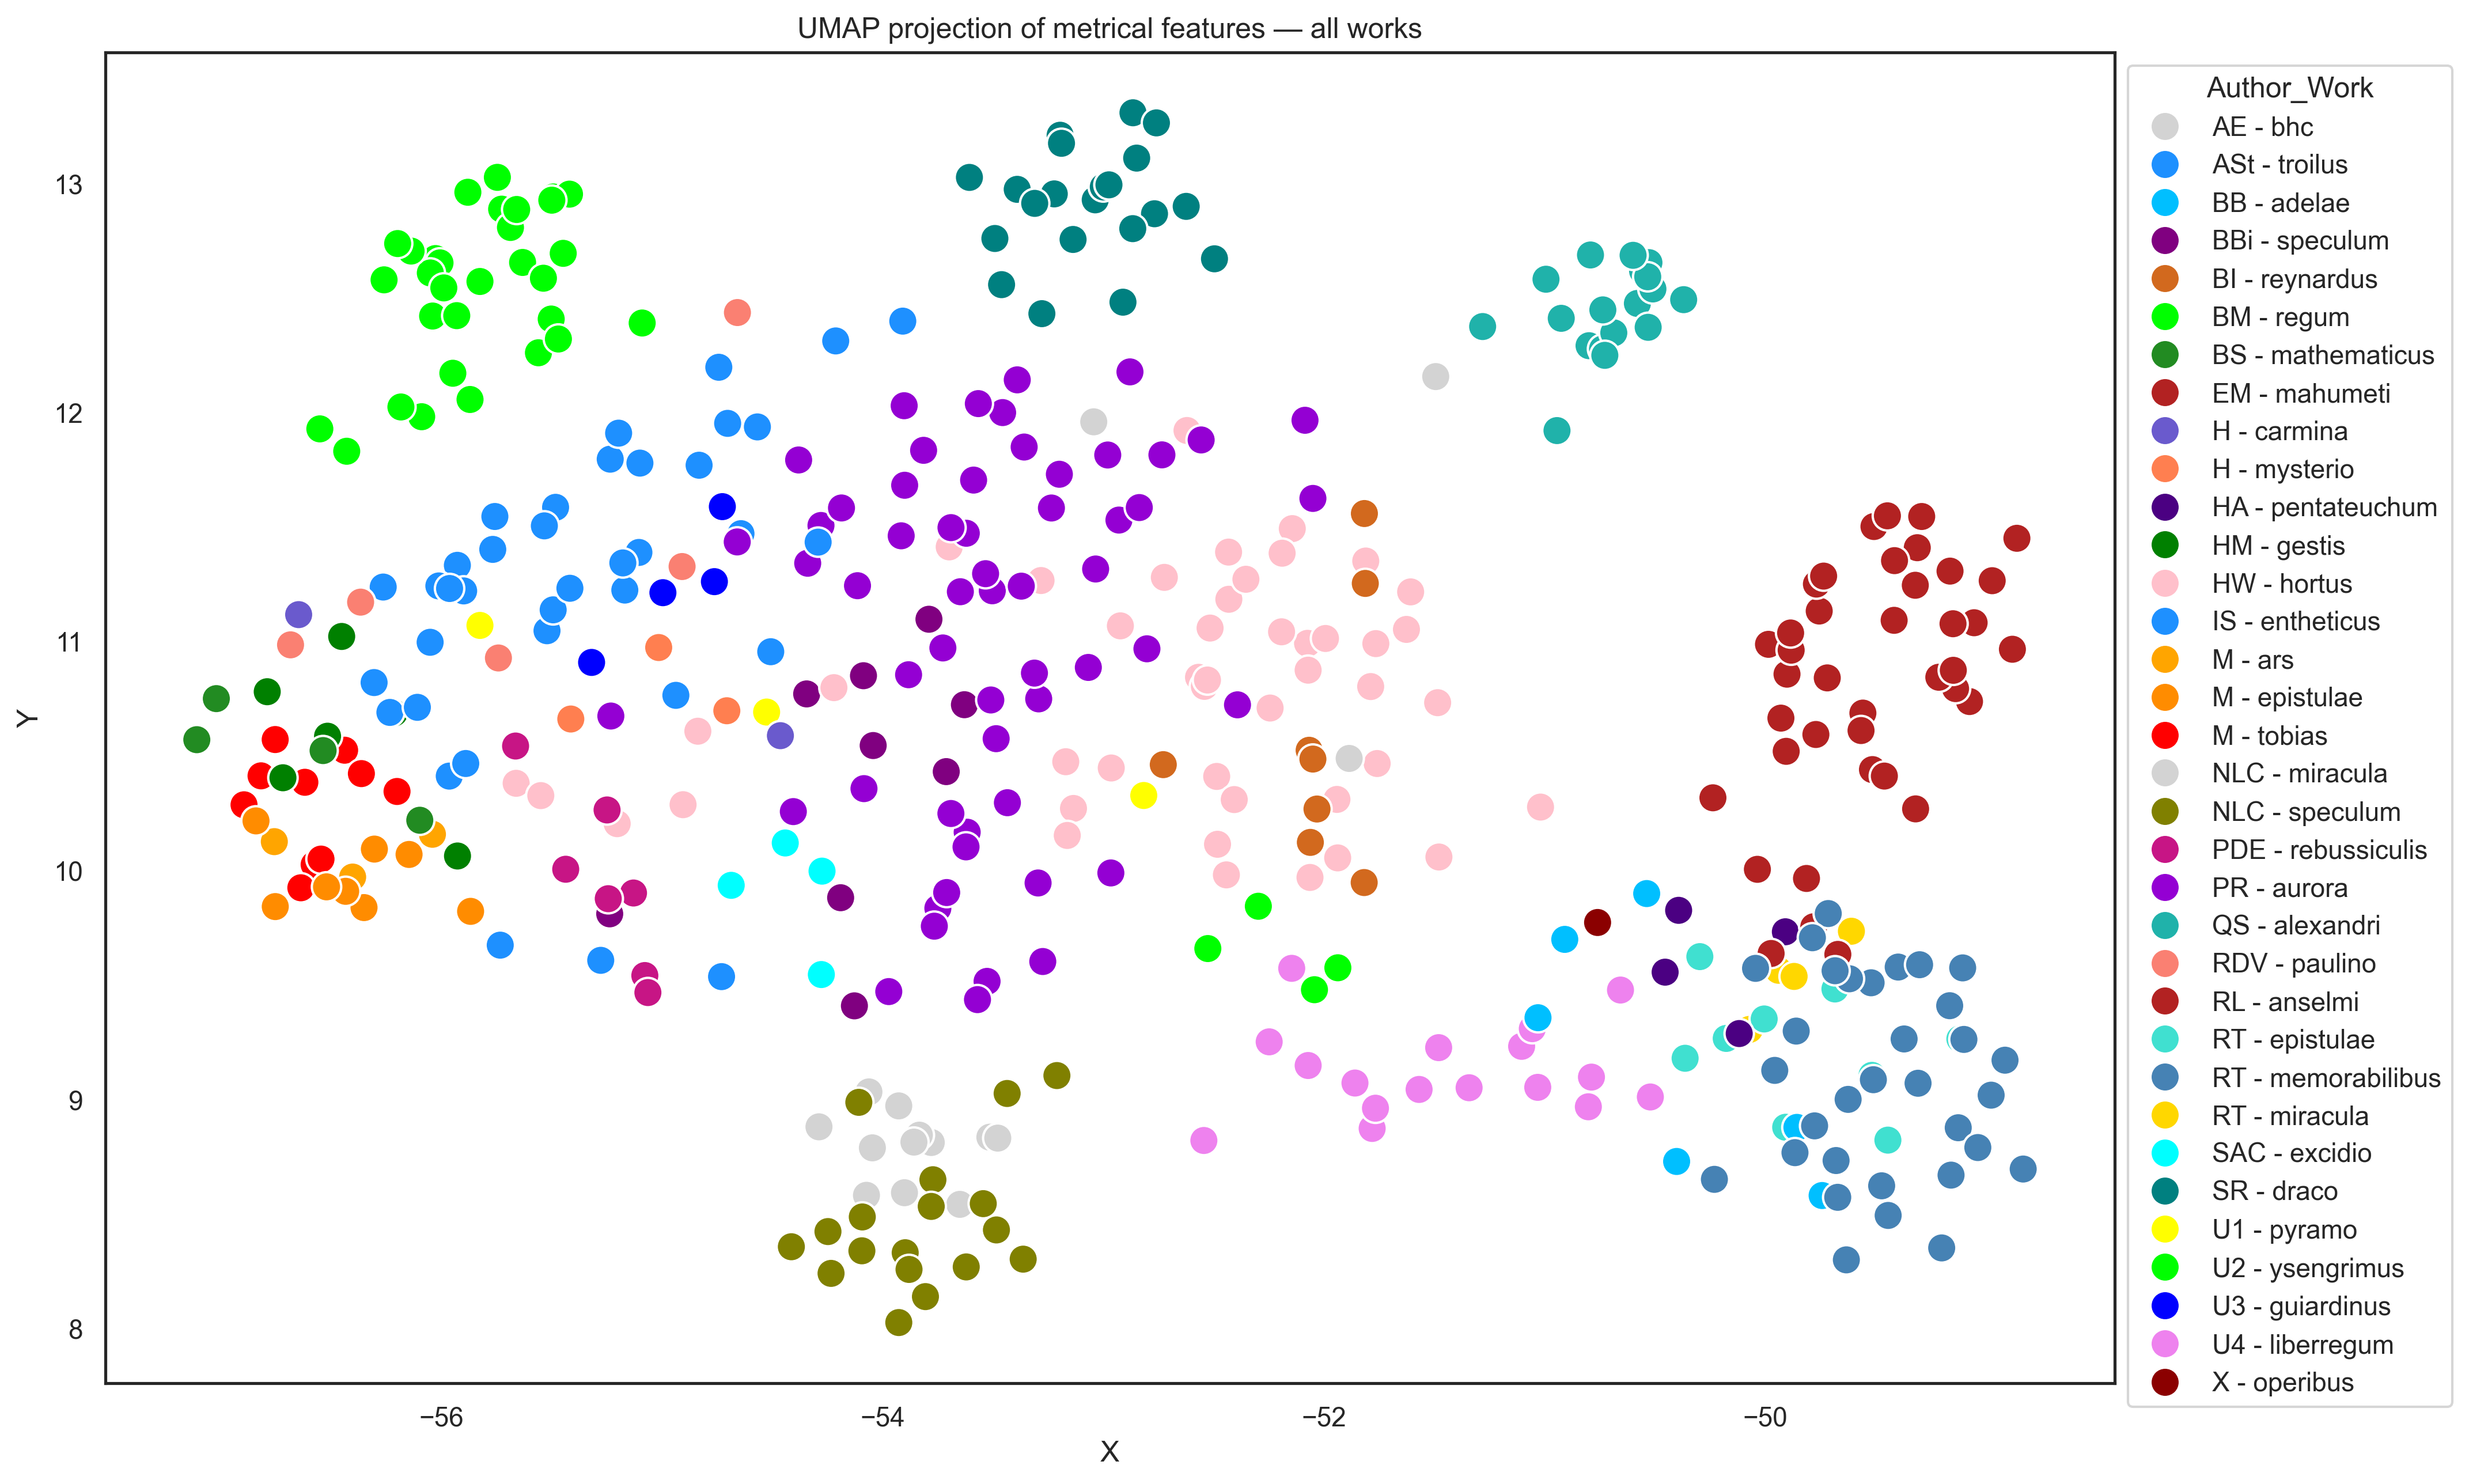

In [41]:
texts_all = [
    'AE - bch', 'ASt - troilus', 'BB - adelae', 'BBi - speculum',
    'BI - reynardus', 'BM - regum', 'BS - mathematicus',
    'EM - mahumeti', 'H - carmina', 'H - mysterio', 'X - operibus',
    'HA - pentateuchum', 'HM - gestis', 'HW - hortus', 'IS - entheticus',
    'LD - hypognosticon', 'M - ars', 'M - epistulae', 'M - tobias',
    'NLC - marie', 'NLC - speculum', 'PDE - rebussiculis',
    'PR - aurora', 'QS - alexandri', 'RDV - paulino', 'RL - anselmi',
    'RT - epistulae', 'RT - memorabilibus', 'RT - miracula',
    'SAC - excidio', 'SR - draco', 'U1 - pyramo',
    'U2 - ysengrimus', 'U3 - guiardinus', 'U4 - liberregum'
]

colors_all = [
    'indigo', 'dodgerblue', 'deepskyblue', 'purple', 'chocolate',
    'lime', 'forestgreen', 'firebrick', 'slateblue', 'coral',
    'darkred', 'indigo', 'green', 'pink', 'dodgerblue', 'brown',
    'orange', 'darkorange', 'red', 'crimson', 'olive',
    'mediumvioletred', 'darkviolet', 'lightseagreen', 'salmon',
    'firebrick', 'turquoise', 'steelblue', 'gold', 'cyan',
    'teal', 'yellow', 'lime', 'blue', 'violet'
]

plot_projection_highlight(
    umap_results,
    texts_all,
    colors_all,
    title="UMAP projection of metrical features — all works",
    collapse_others=False
)

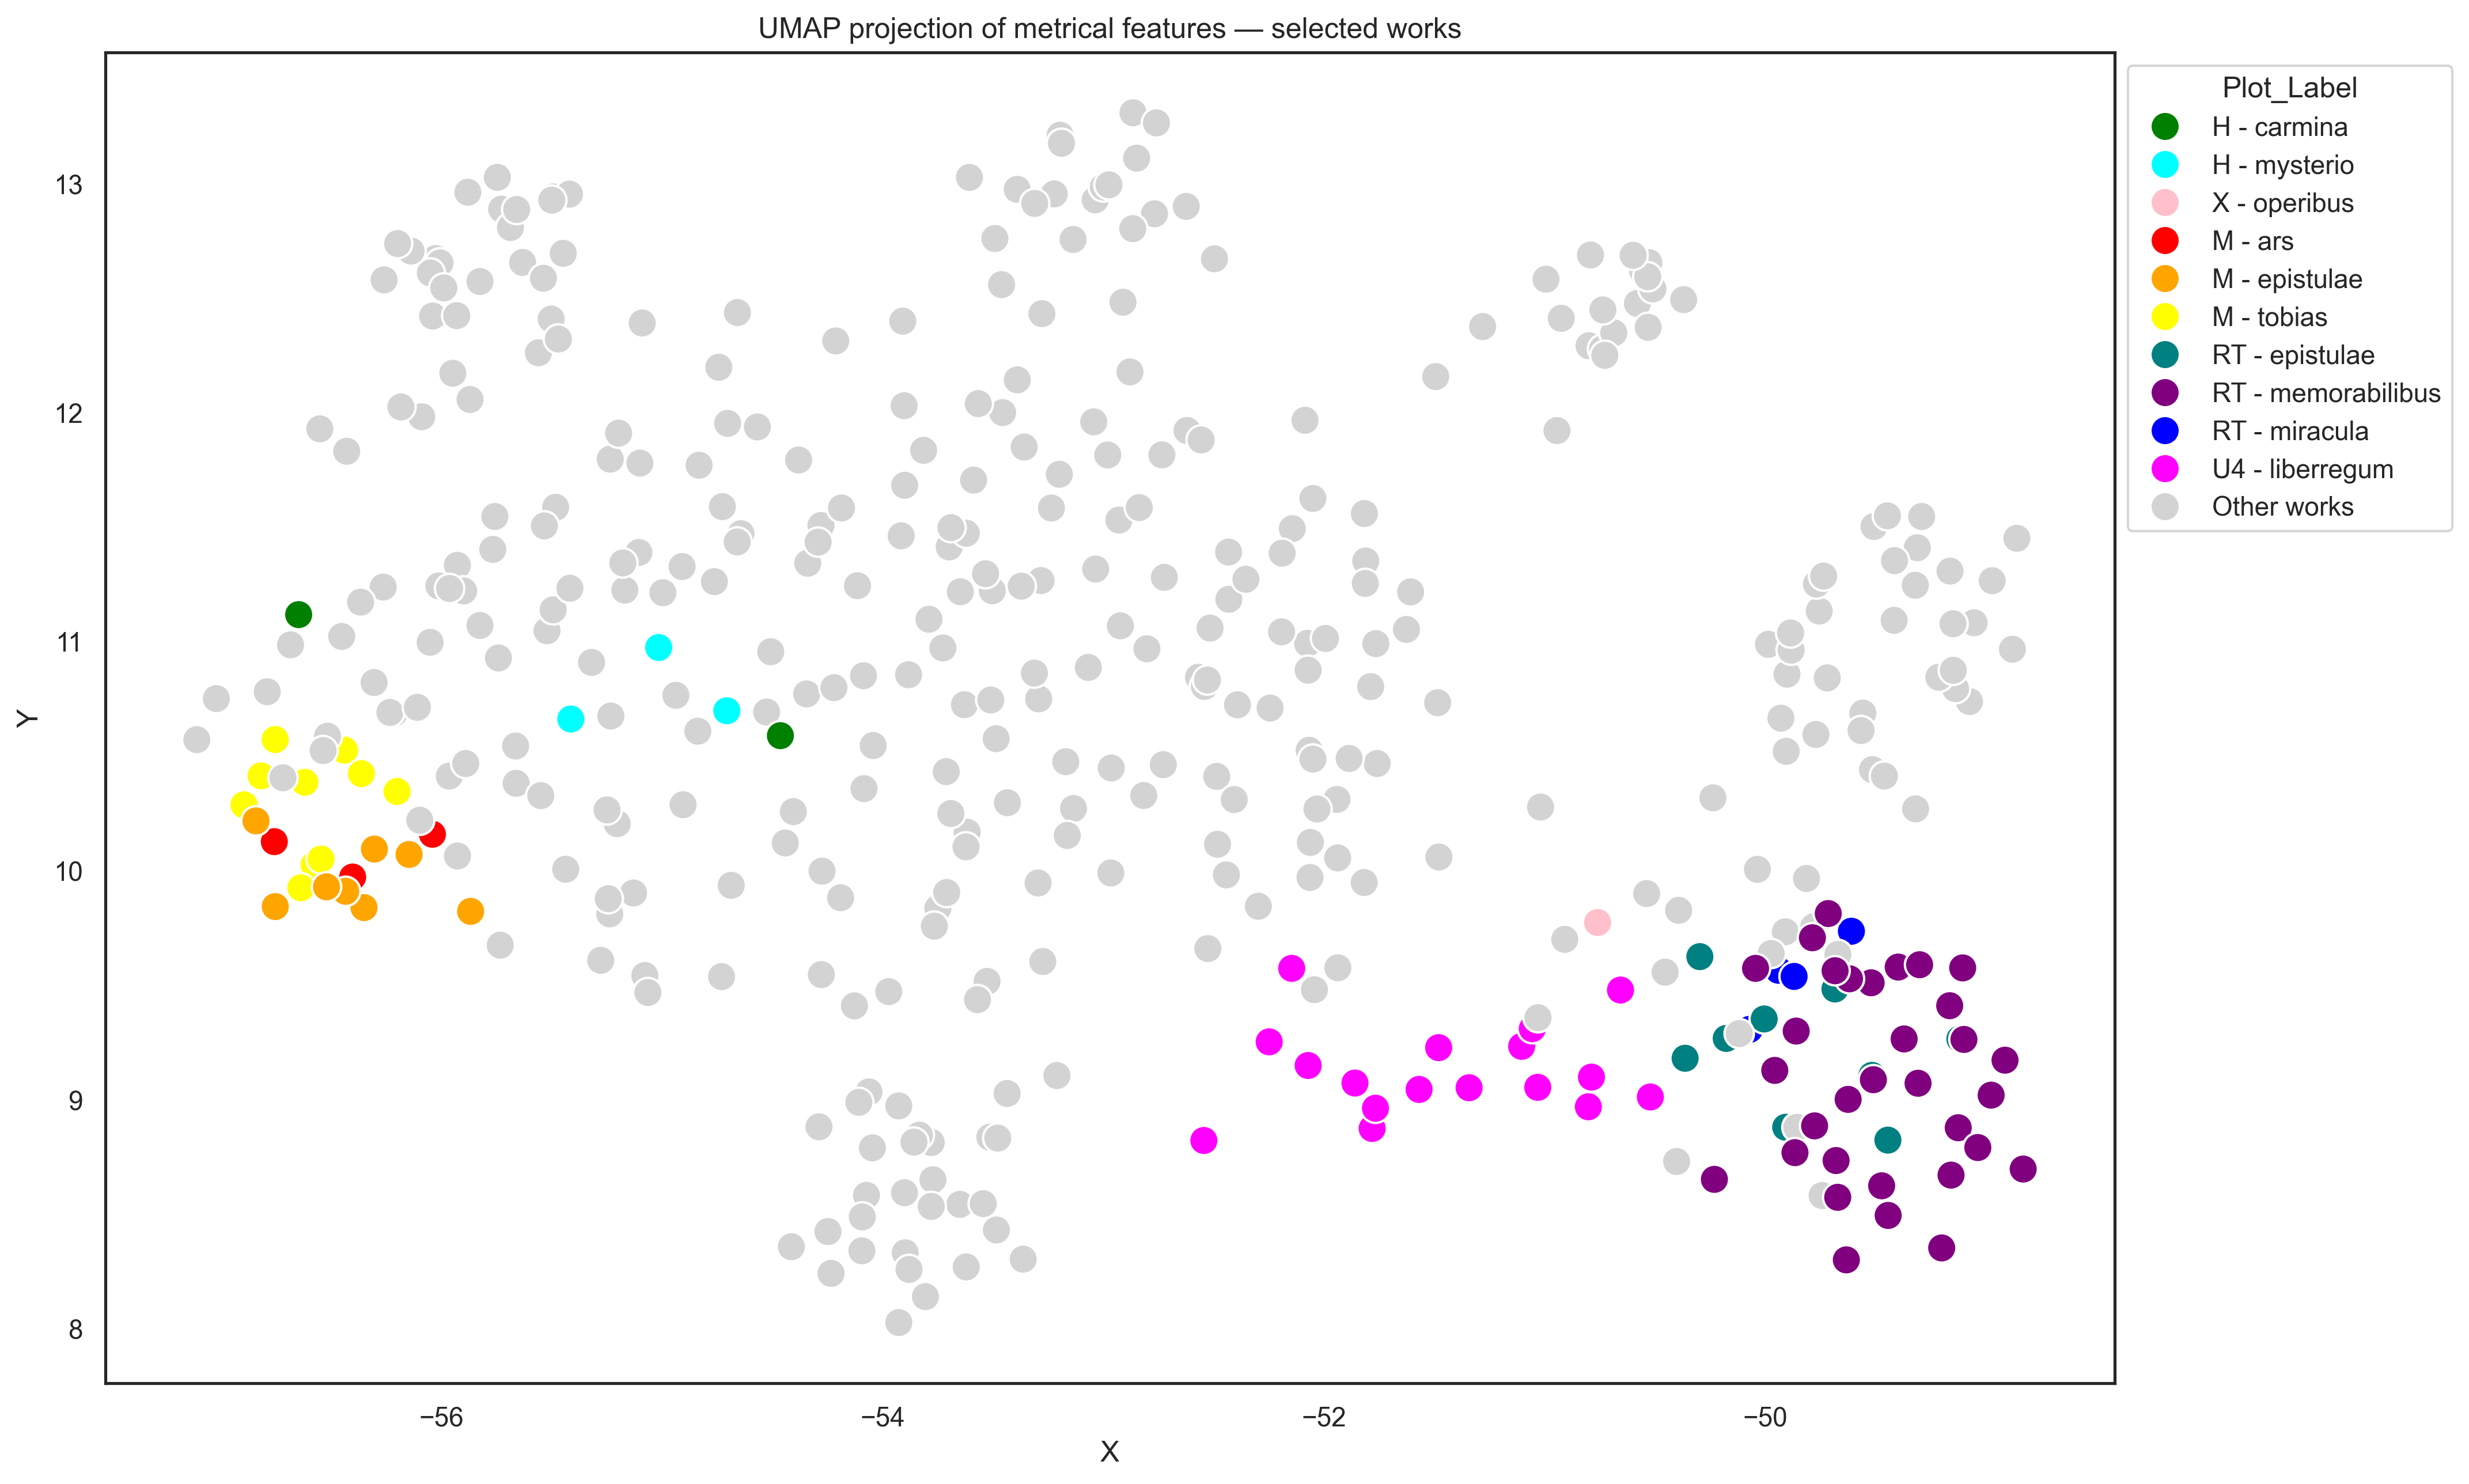

In [42]:
texts_highlight = [
    'H - carmina', 'H - mysterio', 'X - operibus',
    'M - ars', 'M - epistulae', 'M - tobias',
    'RT - epistulae', 'RT - memorabilibus', 'RT - miracula',
    'U4 - liberregum'
]

colors_highlight = [
    'green', 'cyan', 'pink',
    'red', 'orange', 'yellow',
    'teal', 'purple', 'blue',
    'magenta'
]

plot_projection_highlight(
    umap_results,
    texts_highlight,
    colors_highlight,
    title="UMAP projection of metrical features — selected works",
    collapse_others=True
)